# Bab 10: Neural Learning About Edges and Corners — Intro to Convolutional Neural Networks

Notebook ini merangkum Bab 10 buku *Grokking Deep Learning* karya Andrew W. Trask. Bab ini memperkenalkan **convolutional neural network (CNN)**, arsitektur khusus pertama di buku ini. Idenya: kalau pola yang sama perlu dikenali di banyak tempat, pakai weight yang sama di tempat-tempat itu. Cara ini mengurangi overfitting dan meningkatkan generalisasi.

Isi notebook:

1. Memakai ulang weight di banyak tempat
2. Convolutional layer dan kernel
3. Pooling (sum, mean, max)
4. Implementasi sederhana di NumPy
5. Rangkuman: *structure trick*

## 1. Memakai Ulang Weight di Banyak Tempat

Tantangan terbesar neural network adalah **overfitting**: network menghafal dataset alih-alih mempelajari abstraksi berguna yang bisa digeneralisasi. Network mempelajari noise, bukan sinyal (ingat analogi garpu di tanah liat).

Overfitting sering terjadi karena parameter lebih banyak daripada yang diperlukan untuk mempelajari dataset. Network punya begitu banyak parameter sehingga bisa menghafal setiap detail data latih ("Ah, gambar nomor 363 lagi. Ini angka 2") alih-alih mempelajari abstraksi tingkat tinggi ("Ada lengkung di atas, putaran di kiri bawah, dan ekor di kanan, pasti angka 2"). Kalau parameter banyak sementara contoh latih sedikit, overfitting sulit dihindari.

Bab 8 membahas regularisasi sebagai cara melawannya. Tetapi regularisasi bukan satu-satunya teknik, dan belum tentu yang paling ideal. Overfitting bergantung pada rasio antara jumlah weight dan jumlah datapoint untuk mempelajarinya. Jadi ada cara yang lebih baik: memakai sesuatu yang secara longgar disebut **struktur**.

> **Struktur**: kita sengaja memakai ulang weight untuk beberapa tujuan di dalam network, karena kita yakin pola yang sama perlu dideteksi di beberapa tempat.

Cara ini menurunkan rasio weight terhadap data. Biasanya, mengurangi parameter membuat model kurang ekspresif. Tetapi kalau cerdik dalam memilih tempat memakai ulang weight, model bisa tetap sama ekspresifnya namun lebih tahan overfitting. Efek sampingnya, model juga cenderung lebih kecil karena parameter aktualnya lebih sedikit.

Struktur yang paling terkenal dan paling banyak dipakai adalah **konvolusi**. Jika dipakai sebagai layer, ia disebut **convolutional layer**.

## 2. Convolutional Layer

Gagasan intinya: alih-alih satu layer linear besar yang menghubungkan setiap input ke setiap output, kita punya banyak layer linear kecil yang dipakai ulang di setiap posisi. Tiap layer mini biasanya punya kurang dari 25 input dan satu output. Setiap layer mini ini disebut **convolutional kernel**, yang pada dasarnya hanya "layer linear bayi" dengan sedikit input dan satu output.

Sebuah kernel 3 × 3 bekerja begini:

1. Ia membuat prediksi di posisi saat ini.
2. Bergeser satu piksel ke kanan dan memprediksi lagi, dan seterusnya sampai menyapu seluruh lebar gambar.
3. Lalu turun satu piksel, menyapu kembali ke kiri, dan mengulang sampai ada prediksi di setiap posisi yang mungkin.

Hasilnya adalah persegi yang lebih kecil berisi prediksi kernel, yang menjadi input untuk layer berikutnya. Convolutional layer biasanya punya banyak kernel.

Contoh di buku: empat kernel 3 × 3 yang berbeda memproses gambar 8 × 8 berisi angka 2. Tiap kernel menghasilkan matriks prediksi 6 × 6, jadi hasil layer adalah empat matriks 6 × 6. Perhatikan:

- Satu kernel hanya meneruskan nilai 1 jika ia sedang melihat segmen garis **horizontal**.
- Kernel lain hanya meneruskan 1 jika melihat garis **diagonal** yang naik ke kanan atas.
- Kernel lain mungkin tidak menemukan pola yang dilatihkan padanya sama sekali.

Setiap kernel mempelajari sebuah pola, lalu mencari keberadaan pola itu di mana pun dalam gambar. Satu set kecil weight dilatih pada contoh yang jauh lebih banyak, karena walaupun datasetnya tidak berubah, tiap kernel di-forward-propagate berkali-kali pada banyak segmen data. Rasio weight terhadap datapoint berubah, dan inilah yang sangat mengurangi kemampuan overfit sekaligus meningkatkan kemampuan generalisasi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2, suppress=True, linewidth=120)

# Gambar 8x8 sederhana menyerupai angka "2" (buatan sendiri untuk ilustrasi)
img = np.array([
    [0, 0, 1, 1, 1, 1, 0, 0],
    [0, 1, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 0, 1, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
], dtype=float)

# Empat kernel 3x3: horizontal, vertikal, diagonal naik ke kanan, diagonal turun ke kanan
kernels_demo = {
    "horizontal": np.array([[0, 0, 0], [1, 1, 1], [0, 0, 0]], dtype=float),
    "vertikal":   np.array([[0, 1, 0], [0, 1, 0], [0, 1, 0]], dtype=float),
    "diagonal /": np.array([[0, 0, 1], [0, 1, 0], [1, 0, 0]], dtype=float),
    "diagonal \\": np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=float),
}


def convolve_valid(image, kernel):
    """Geser kernel ke setiap posisi yang mungkin, hitung weighted sum (dot product)."""
    kr, kc = kernel.shape
    out_r = image.shape[0] - kr + 1
    out_c = image.shape[1] - kc + 1
    out = np.zeros((out_r, out_c))
    for r in range(out_r):
        for c in range(out_c):
            out[r, c] = np.sum(image[r:r+kr, c:c+kc] * kernel)
    return out


outputs = {name: convolve_valid(img, k) for name, k in kernels_demo.items()}
print("Ukuran output tiap kernel:", next(iter(outputs.values())).shape)

Ukuran output tiap kernel: (6, 6)


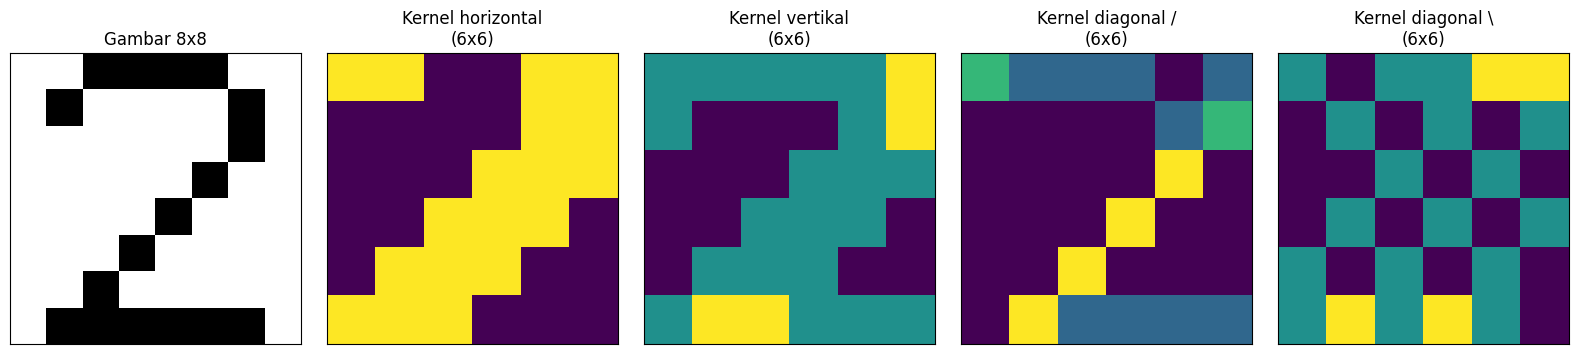

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
axes[0].imshow(img, cmap="gray_r")
axes[0].set_title("Gambar 8x8")
for ax, (name, out) in zip(axes[1:], outputs.items()):
    ax.imshow(out, cmap="viridis")
    ax.set_title(f"Kernel {name}\n(6x6)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Terlihat bahwa setiap kernel "menyala" di bagian gambar yang cocok dengan polanya. Kernel horizontal menyala di garis atas dan bawah angka 2, sedangkan kernel diagonal menyala di batang miringnya.

## 3. Pooling: Menggabungkan Output Banyak Kernel

Hasil convolutional layer dengan empat kernel 3 × 3 adalah empat matriks prediksi 6 × 6. Kita bisa menggabungkannya menjadi satu matriks:

- **Sum pooling**: menjumlahkan matriks secara elemen demi elemen.
- **Mean pooling**: mengambil rata-rata elemen demi elemen.
- **Max pooling**: mengambil nilai maksimum elemen demi elemen.

Versi terakhir paling populer. Di setiap posisi, lihat output keempat kernel, ambil yang paling besar, dan salin ke matriks akhir 6 × 6. Matriks akhir inilah (dan hanya ini) yang diteruskan ke layer berikutnya. Kita menanyakan "adakah pola ini di posisi ini?", dan max pooling menjawab dengan nilai kernel yang paling yakin.

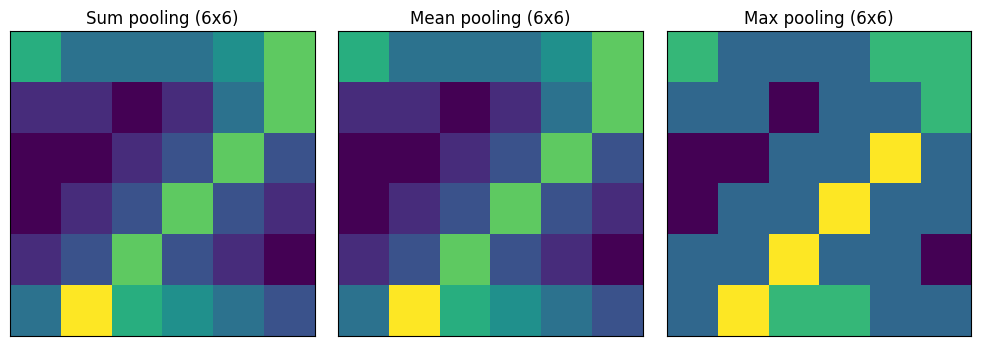

Max pooling:
[[2. 1. 1. 1. 2. 2.]
 [1. 1. 0. 1. 1. 2.]
 [0. 0. 1. 1. 3. 1.]
 [0. 1. 1. 3. 1. 1.]
 [1. 1. 3. 1. 1. 0.]
 [1. 3. 2. 2. 1. 1.]]


In [3]:
stack = np.stack(list(outputs.values()))        # (4, 6, 6)

sum_pool = stack.sum(axis=0)
mean_pool = stack.mean(axis=0)
max_pool = stack.max(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (name, m) in zip(axes, [("Sum", sum_pool), ("Mean", mean_pool), ("Max", max_pool)]):
    ax.imshow(m, cmap="viridis")
    ax.set_title(f"{name} pooling (6x6)")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print("Max pooling:")
print(max_pool)

Catatan: istilah *pooling* di sini mengikuti cara buku menggabungkan output beberapa kernel di tiap posisi. Di banyak framework modern, "pooling" biasanya berarti operasi yang menggabungkan wilayah spasial berdekatan dalam satu peta fitur (misalnya max pool 2 × 2). Maknanya agak berbeda, jadi berhati-hatilah ketika membaca sumber lain.

## 4. Implementasi Sederhana di NumPy

Bayangkan setiap kernel sebagai mini linear layer, dan kita sudah tahu apa yang perlu diketahui. Mulai dari forward propagation. Fungsi berikut memilih sub-wilayah dari sekumpulan (batch) gambar. Sub-wilayah yang sama dipilih untuk seluruh batch.

In [4]:
def get_image_section(layer, row_from, row_to, col_from, col_to):
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to - row_from, col_to - col_from)

Fungsi ini dipanggil berkali-kali, untuk setiap lokasi dalam gambar. Loop-nya kira-kira begini (dengan `layer_0` berupa batch gambar 28 × 28):

```python
sects = list()
for row_start in range(layer_0.shape[1] - kernel_rows):
    for col_start in range(layer_0.shape[2] - kernel_cols):
        sect = get_image_section(layer_0, row_start, row_start + kernel_rows,
                                 col_start, col_start + kernel_cols)
        sects.append(sect)

expanded_input = np.concatenate(sects, axis=1)
es = expanded_input.shape
flattened_input = expanded_input.reshape(es[0] * es[1], -1)
```

Setiap sub-wilayah dikumpulkan di daftar `sects`, digabung, lalu di-reshape dengan cara yang agak unik. **Anggap setiap sub-wilayah itu gambar kecil tersendiri.** Jika batch berisi 8 gambar dan ada 100 sub-wilayah per gambar, bayangkan seolah-olah ada batch 800 gambar kecil. Meneruskan mereka lewat layer linear dengan satu neuron output sama dengan menjalankan layer linear itu di setiap sub-wilayah di setiap gambar batch.

Kalau layer linear punya `n` neuron output, hasilnya sama dengan memprediksi `n` layer linear (kernel) di setiap posisi gambar. Dilakukan seperti ini karena kodenya lebih sederhana dan lebih cepat:

```python
kernels = np.random.random((kernel_rows * kernel_cols, num_kernels))
kernel_output = flattened_input.dot(kernels)
```

Berikut demonstrasi bentuk (shape) array pada satu batch kecil sebelum kita masuk ke kode lengkap.

In [5]:
rng = np.random.RandomState(1)

demo_batch = rng.rand(8, 28, 28)       # 8 gambar acak 28x28
kernel_rows, kernel_cols, num_kernels = 3, 3, 16

sects = []
for row_start in range(demo_batch.shape[1] - kernel_rows):
    for col_start in range(demo_batch.shape[2] - kernel_cols):
        sects.append(get_image_section(demo_batch, row_start, row_start + kernel_rows,
                                       col_start, col_start + kernel_cols))

expanded_input = np.concatenate(sects, axis=1)
es = expanded_input.shape
flattened_input = expanded_input.reshape(es[0] * es[1], -1)

demo_kernels = 0.02 * rng.rand(kernel_rows * kernel_cols, num_kernels) - 0.01
kernel_output = flattened_input.dot(demo_kernels)

print("jumlah sub-wilayah per gambar :", len(sects))
print("expanded_input.shape          :", es)
print("flattened_input.shape         :", flattened_input.shape)
print("kernel_output.shape           :", kernel_output.shape)
print("hasil per gambar (di-reshape) :", kernel_output.reshape(es[0], -1).shape)

jumlah sub-wilayah per gambar : 625
expanded_input.shape          : (8, 625, 3, 3)
flattened_input.shape         : (5000, 9)
kernel_output.shape           : (5000, 16)
hasil per gambar (di-reshape) : (8, 10000)


Sekarang implementasi lengkap CNN di NumPy. Struktur network:

- **Layer 1**: convolutional layer dengan 16 kernel berukuran 3 × 3, diikuti `tanh` dan dropout.
- **Layer 2**: layer linear penuh ke 10 output dengan `softmax`.

Hal-hal yang perlu diperhatikan:

- `hidden_size = (input_rows - kernel_rows) * (input_cols - kernel_cols) * num_kernels`. Pada listing buku, loop menyapu `range(28 - 3)` posisi tiap sumbu (25 posisi), jadi `hidden_size` = 25 × 25 × 16 = 10.000. (Sapuan yang sebenarnya lengkap akan punya 26 posisi tiap sumbu; kode buku melewatkan posisi terakhir. Kita ikuti buku apa adanya.)
- Pembaruan kernel memakai delta dari `layer_1` yang di-reshape sesuai `kernel_output`, lalu dikalikan `flattened_input.T`. Karena kernel yang sama dipakai di setiap posisi, gradiennya dijumlahkan dari semua posisi.

Muat MNIST dulu.

In [6]:
import sys
import numpy as np

np.random.seed(1)

# Memuat MNIST. Buku memakai keras; kalau tidak tersedia, dipakai OpenML lewat scikit-learn.
try:
    from keras.datasets import mnist
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
except Exception:
    from sklearn.datasets import fetch_openml
    mn = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
    X_all, y_all = mn.data.astype("float64"), mn.target.astype(int)
    x_train, y_train = X_all[:60000], y_all[:60000]
    x_test, y_test = X_all[60000:], y_all[60000:]

# 1000 gambar pertama untuk latihan, seluruh data uji untuk evaluasi
images = x_train[0:1000].reshape(1000, 28 * 28) / 255
labels = y_train[0:1000]

one_hot_labels = np.zeros((len(labels), 10))
for i, l in enumerate(labels):
    one_hot_labels[i][l] = 1
labels = one_hot_labels

test_images = x_test.reshape(len(x_test), 28 * 28) / 255
test_labels = np.zeros((len(y_test), 10))
for i, l in enumerate(y_test):
    test_labels[i][l] = 1

print(images.shape, labels.shape, test_images.shape, test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(1000, 784) (1000, 10) (10000, 784) (10000, 10)


In [7]:
def tanh(x):
    return np.tanh(x)

def tanh2deriv(output):
    return 1 - (output ** 2)

def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)


# ----- Pengaturan -----
# Nilai buku: iterations=300, evaluasi seluruh 10.000 gambar uji tiap iterasi.
# Itu SANGAT lambat dengan loop Python; perkecil untuk mencoba cepat.
alpha, iterations = (2, 300)
pixels_per_image, num_labels = (784, 10)
batch_size = 128

input_rows = 28
input_cols = 28

kernel_rows = 3
kernel_cols = 3
num_kernels = 16

n_test_eval = len(test_images)     # mis. ganti 1000 untuk evaluasi lebih cepat

hidden_size = ((input_rows - kernel_rows) *
               (input_cols - kernel_cols)) * num_kernels

kernels = 0.02 * np.random.random((kernel_rows * kernel_cols, num_kernels)) - 0.01
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1


def get_image_section(layer, row_from, row_to, col_from, col_to):
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to - row_from, col_to - col_from)


def expand_sections(layer_0):
    """Ubah batch gambar (n, 28, 28) menjadi matriks sub-wilayah siap dikali kernel."""
    sects = list()
    for row_start in range(layer_0.shape[1] - kernel_rows):
        for col_start in range(layer_0.shape[2] - kernel_cols):
            sect = get_image_section(layer_0,
                                     row_start, row_start + kernel_rows,
                                     col_start, col_start + kernel_cols)
            sects.append(sect)
    expanded_input = np.concatenate(sects, axis=1)
    es = expanded_input.shape
    flattened_input = expanded_input.reshape(es[0] * es[1], -1)
    return es, flattened_input

In [8]:
for j in range(iterations):
    correct_cnt = 0

    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))

        layer_0 = images[batch_start:batch_end]
        layer_0 = layer_0.reshape(layer_0.shape[0], 28, 28)

        es, flattened_input = expand_sections(layer_0)

        kernel_output = flattened_input.dot(kernels)
        layer_1 = tanh(kernel_output.reshape(es[0], -1))

        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2

        layer_2 = softmax(np.dot(layer_1, weights_1_2))

        for k in range(batch_size):
            labelset = labels[batch_start + k:batch_start + k + 1]
            _inc = int(np.argmax(layer_2[k:k+1]) == np.argmax(labelset))
            correct_cnt += _inc

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) \
                        / (batch_size * layer_2.shape[0])
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)

        l1d_reshape = layer_1_delta.reshape(kernel_output.shape)
        k_update = flattened_input.T.dot(l1d_reshape)
        kernels -= alpha * k_update

    test_correct_cnt = 0
    for i in range(n_test_eval):
        layer_0 = test_images[i:i+1]
        layer_0 = layer_0.reshape(layer_0.shape[0], 28, 28)

        es, flattened_input = expand_sections(layer_0)

        kernel_output = flattened_input.dot(kernels)
        layer_1 = tanh(kernel_output.reshape(es[0], -1))
        layer_2 = np.dot(layer_1, weights_1_2)

        test_correct_cnt += int(np.argmax(layer_2) == np.argmax(test_labels[i:i+1]))

    if j % 1 == 0:
        sys.stdout.write("\n" + "I:" + str(j) +
                         " Test-Acc:" + str(test_correct_cnt / float(n_test_eval)) +
                         " Train-Acc:" + str(correct_cnt / float(len(images))))


I:0 Test-Acc:0.0414 Train-Acc:0.094
I:1 Test-Acc:0.0502 Train-Acc:0.039
I:2 Test-Acc:0.0425 Train-Acc:0.059
I:3 Test-Acc:0.0472 Train-Acc:0.051
I:4 Test-Acc:0.0546 Train-Acc:0.065
I:5 Test-Acc:0.0688 Train-Acc:0.094
I:6 Test-Acc:0.101 Train-Acc:0.108
I:7 Test-Acc:0.1563 Train-Acc:0.117
I:8 Test-Acc:0.2312 Train-Acc:0.146
I:9 Test-Acc:0.3 Train-Acc:0.169
I:10 Test-Acc:0.365 Train-Acc:0.196
I:11 Test-Acc:0.4163 Train-Acc:0.222
I:12 Test-Acc:0.454 Train-Acc:0.279
I:13 Test-Acc:0.476 Train-Acc:0.276
I:14 Test-Acc:0.4665 Train-Acc:0.307
I:15 Test-Acc:0.3686 Train-Acc:0.247
I:16 Test-Acc:0.1923 Train-Acc:0.186
I:17 Test-Acc:0.1105 Train-Acc:0.098
I:18 Test-Acc:0.07 Train-Acc:0.07
I:19 Test-Acc:0.0479 Train-Acc:0.053
I:20 Test-Acc:0.0313 Train-Acc:0.047
I:21 Test-Acc:0.0327 Train-Acc:0.046
I:22 Test-Acc:0.0589 Train-Acc:0.045
I:23 Test-Acc:0.127 Train-Acc:0.07
I:24 Test-Acc:0.2318 Train-Acc:0.099
I:25 Test-Acc:0.3266 Train-Acc:0.163
I:26 Test-Acc:0.4192 Train-Acc:0.199
I:27 Test-Acc:0.4977 T

Cuplikan hasil di buku: akurasi awal sangat rendah (Test-Acc sekitar 0,03 pada iterasi 0 sampai 4), lalu naik, dan di iterasi ~297–299 mencapai **Test-Acc ≈ 0,8774** dengan Train-Acc sekitar 0,80–0,82. Dibanding network Bab 9 (sekitar 87%), mengganti layer pertama dengan convolutional layer memberi pengurangan error beberapa persen lagi.

Keluaran dari convolutional layer (`kernel_output`) sendiri juga serangkaian gambar dua dimensi (output tiap kernel di tiap posisi input). Kebanyakan pemakaian convolutional layer menumpuk beberapa layer, sehingga tiap layer konvolusi memperlakukan layer sebelumnya sebagai gambar input. Buku mengajak kita mencobanya sebagai proyek pribadi, karena akan menaikkan akurasi lebih jauh.

Convolutional layer yang ditumpuk adalah salah satu perkembangan utama yang memungkinkan network yang sangat dalam (dan, lewat itu, populernya istilah *deep learning*). Buku menyebutnya momen bersejarah bagi bidang ini.

## 5. Rangkuman: Memakai Ulang Weight adalah Inovasi Penting

CNN adalah pengembangan yang lebih umum daripada yang kita kira. Ide memakai ulang weight untuk meningkatkan akurasi sangat penting dan punya dasar yang intuitif. Untuk mendeteksi kucing di gambar, kita perlu memahami warna, lalu garis dan tepi, sudut dan bentuk kecil, dan akhirnya kombinasi fitur tingkat rendah itu yang bersesuaian dengan kucing. Network juga perlu belajar tentang fitur tingkat rendah ini (garis, tepi), dan kecerdasan untuk mendeteksinya dipelajari di weight.

Kalau kita memakai weight berbeda untuk menganalisis bagian gambar yang berbeda, tiap bagian weight harus mempelajari sendiri apa itu garis. Tidak ada alasan menganggap weight di bagian lain bisa memakai pengetahuan itu, karena ia berada di bagian network yang berbeda.

> **The structure trick**: ketika neural network perlu memakai ide yang sama di beberapa tempat, usahakan memakai weight yang sama di tempat-tempat itu. Ini membuat weight tersebut lebih cerdas karena mendapat lebih banyak sampel untuk belajar, sehingga meningkatkan generalisasi.

Banyak perkembangan terbesar deep learning dalam beberapa tahun terakhir adalah turunan ide ini: konvolusi, recurrent neural network (RNN), word embedding, dan capsule network. Ketika kita tahu network akan membutuhkan ide yang sama di banyak tempat, paksa ia memakai weight yang sama di tempat-tempat itu.

In [9]:
# Perbandingan jumlah parameter: layer penuh vs convolutional (untuk input 28x28, 10.000 unit hidden)
dense_params = (28 * 28) * 10000                  # satu weight per pasangan input-hidden
conv_params = kernel_rows * kernel_cols * num_kernels  # kernel dipakai ulang di semua posisi

print(f"Layer penuh (784 -> 10.000)  : {dense_params:,} weight")
print(f"Convolutional ({kernel_rows}x{kernel_cols}, {num_kernels} kernel): {conv_params:,} weight")
print(f"Rasio                        : {dense_params / conv_params:,.0f}x lebih banyak pada layer penuh")

Layer penuh (784 -> 10.000)  : 7,840,000 weight
Convolutional (3x3, 16 kernel): 144 weight
Rasio                        : 54,444x lebih banyak pada layer penuh


## Poin-poin Penting Bab 10

- **Overfitting** sering disebabkan jumlah parameter yang lebih banyak daripada yang dibutuhkan. Selain regularisasi, cara yang lebih baik adalah **struktur**: memakai ulang weight yang sama di tempat-tempat yang membutuhkan pola yang sama.
- **Convolutional layer** terdiri dari banyak layer linear kecil (kernel, biasanya kurang dari 25 input dan satu output) yang digeser ke setiap posisi gambar. Banyak kernel menghasilkan banyak peta prediksi.
- Tiap kernel belajar mendeteksi satu pola (misalnya garis horizontal atau diagonal) dan mencarinya di mana pun dalam gambar. Satu set weight kecil dilatih pada banyak sekali sub-wilayah data, sehingga rasio weight terhadap datapoint berubah dan overfitting berkurang.
- Output beberapa kernel dapat digabung dengan **sum**, **mean**, atau **max pooling**, dan max pooling paling populer.
- Di NumPy, sub-wilayah dikumpulkan lalu di-reshape menjadi "batch gambar kecil" supaya satu perkalian matriks (`flattened_input.dot(kernels)`) menjalankan semua kernel di semua posisi sekaligus.
- Mengganti layer pertama network MNIST dengan convolutional layer menaikkan akurasi uji ke sekitar 87,7% di buku. Menumpuk beberapa convolutional layer adalah dasar dari network yang sangat dalam.
- **Structure trick**: kalau network membutuhkan ide yang sama di banyak tempat, pakai weight yang sama. Konvolusi, RNN, dan word embedding adalah contoh penerapan prinsip ini.

Referensi: Trask, A. W. (2019). *Grokking Deep Learning*, Bab 10 "Neural Learning About Edges and Corners: Intro to Convolutional Neural Networks". Manning Publications.